# Homework # 4 Naive BAYES Classifier

### Instructor - Dr. Uma Gajendragadkar

### Problem - Design and develop Machine learning model to predict Diabetes using Naive Bayes Algorithm. 

### Dataset - Diabetes dataset

This dataset consists of 768 observations & 8 numerical independent variables.
Dependent and target variable is OUTCOME. 1 means diabetes test result being positive, 0 means indicates negative.

Pregnancies: Number of Times Being Pregnant

Glucose: Plasma Glucose Concentration (a 2 hours in an oral glucose tolerance test)

BloodPressure: Diastolic Blood Pressure (mm Hg)

SkinThickness: Triceps Skin Fold Thickness (mm)

Insulin: 2-Hour Serum Insulin (mu U/ml)

BMI: Body Mass Index (weight in kg/(height in m)^2)

DiabetesPedigreeFunction: Diabetes Pedigree Function

Age: Age

Outcome: Class variable ( 0 - 1)



In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split, cross_validate
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot  as plt
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score
from sklearn import preprocessing
from sklearn.naive_bayes import GaussianNB

Step 1 - Write code to Read data from dataset into pandas dataframe

In [2]:
df = pd.read_csv("diabetes.csv")

Step 2 - a) Write code to display dataset info 
b) Print 10 rows from dataset.

In [3]:
df.info()
df.head(10)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1
5,5,116,74,0,0,25.600,0.201,30,0
6,3,78,50,32,88,31.000,0.248,26,1
7,10,115,0,0,0,35.300,0.134,29,0
8,2,197,70,45,543,30.500,0.158,53,1
9,8,125,96,0,0,0.000,0.232,54,1


Step 3 - Write code to remove Pregnancy column 

In [4]:
df = df.drop(columns=["Pregnancies"])

Step 4 - Write code to display info of dataset and check shape of dataset.

In [5]:
df.info()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 8 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Glucose                   768 non-null    int64  
 1   BloodPressure             768 non-null    int64  
 2   SkinThickness             768 non-null    int64  
 3   Insulin                   768 non-null    int64  
 4   BMI                       768 non-null    float64
 5   DiabetesPedigreeFunction  768 non-null    float64
 6   Age                       768 non-null    int64  
 7   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(6)
memory usage: 48.1 KB


(768, 8)

Step 5 - Write code to clean data

In [7]:
df = df.drop_duplicates()
df = df.dropna()

Step 6 - Split data into training and testing sets ( 80: 20 ratio)

In [10]:
X = df.drop(columns=["Outcome"])
y = df["Outcome"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)


#### **Step #7: Initialize your model**




In [11]:
nb_model = GaussianNB()

#### **Step #8: Fit your model, test on the testing data, and create a visualization if applicable**

Training Accuracy: 0.7541
Testing Accuracy:  0.7597


<Figure size 1000x500 with 0 Axes>

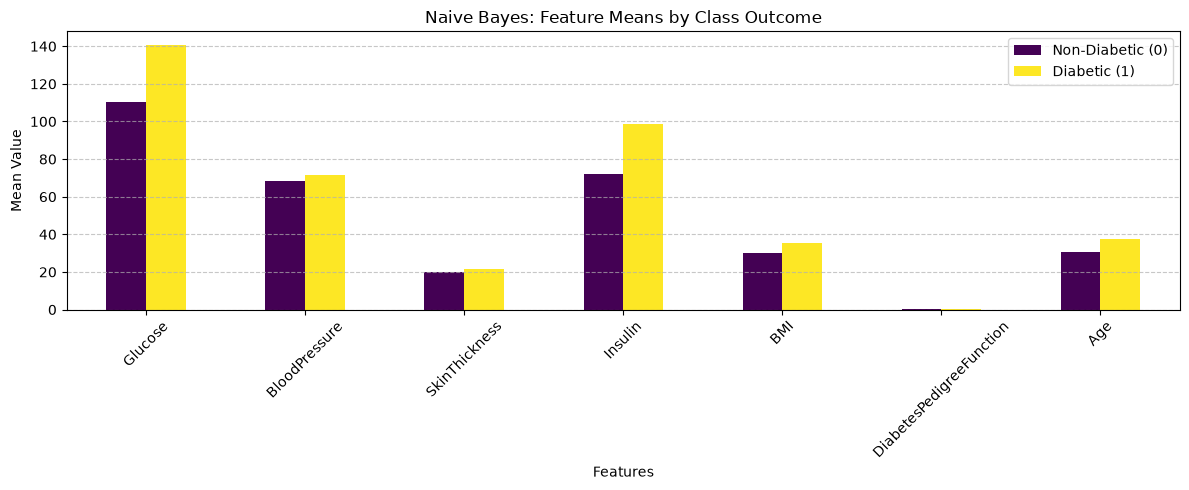

In [12]:
#fit
nb_model.fit(X_train, y_train)

#test
train_score = nb_model.score(X_train, y_train)
test_score = nb_model.score(X_test, y_test)

print(f"Training Accuracy: {train_score:.4f}")
print(f"Testing Accuracy:  {test_score:.4f}")

#visualization
means_df = pd.DataFrame(
    nb_model.theta_,
    columns=X.columns,
    index=["Non-Diabetic (0)", "Diabetic (1)"],
)

plt.figure(figsize=(10, 5))
means_df.T.plot(kind="bar", figsize=(12, 5), colormap="viridis")
plt.title("Naive Bayes: Feature Means by Class Outcome")
plt.ylabel("Mean Value")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


Step 9 - Predict using model on test data

In [13]:
y_pred = nb_model.predict(X_test)

comparison = pd.DataFrame(
    {"Actual Outcome": y_test.values[:10], "Predicted Outcome": y_pred[:10]}
)
print("Sample of Actual vs Predicted Outcomes:")
print(comparison)


Sample of Actual vs Predicted Outcomes:
   Actual Outcome  Predicted Outcome
0               0                  0
1               0                  0
2               0                  0
3               0                  0
4               0                  0
5               0                  0
6               0                  0
7               0                  1
8               0                  0
9               0                  1


Step 10 -  Find accuracy of model

In [14]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy on Test Set: {accuracy:.4f} ({accuracy * 100:.2f}%)")

Model Accuracy on Test Set: 0.7597 (75.97%)


Step 11 - Confusion Matrix

In [16]:
#confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

# classification
print("\nClassification Report:")
print(classification_report(y_test, y_pred))



Confusion Matrix:
[[81 18]
 [19 36]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.82      0.81        99
           1       0.67      0.65      0.66        55

    accuracy                           0.76       154
   macro avg       0.74      0.74      0.74       154
weighted avg       0.76      0.76      0.76       154

